# TF-IDF + Ridge

Training and evaluation on preprocessed property listings. EDA and dataset cleaning belong to `notebooks/`.

## 1. Setup

In [1]:
from pathlib import Path
import os
import sys

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "experiments").is_dir() and (path / "requirements.txt").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["OPENBLAS_NUM_THREADS"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from experiments.data import load_data, default_data_path, SEED, NUMERIC, CATEGORICAL
from experiments.evaluation import (
    select_candidate, inverse_log, record_result, diagnostics,
    importance_plot, comparison_table,
)
from experiments.estimators import (
    structured_preprocessor, native_features, catboost_features,
    text_pipeline, text_inputs, MedianPricePerSqm,
)

np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
DATA_PATH = default_data_path()  # Replace with another preprocessed Parquet path if needed.

## 2. Load Preprocessed Data

The default input is `data/processed/priced_listings.parquet`, exported by the EDA notebook. If it is absent, the existing `experiment_cohort.parquet` is used and its path is displayed below. Set `DATA_PATH` to select a file explicitly. Existing split labels are reused; otherwise a shared 70/15/15 split is created. Every input row is retained. No source download, EDA, cleaning, sampling, or deduplication runs here.

In [2]:
parts, manifest = load_data(DATA_PATH)
train, validation, test = (parts[name] for name in ["train", "validation", "test"])
y_train = train.price.to_numpy()
y_validation = validation.price.to_numpy()
log_y_train = np.log1p(y_train)
log_y_validation = np.log1p(y_validation)
display(pd.Series({"Input": manifest["input_path"], "Seed": SEED,
                   "Split": manifest["split_method"],
                   **manifest["split_counts"]}, name="Training settings").to_frame())

,Training settings
Input,data/processed/experiment_cohort.parquet
Seed,42
Split,existing split column (unchanged)
train,41663
validation,8928
test,8928


## 3. Model

The primary experiment uses only the redacted concatenation of listing title and description; no structured columns are appended. A Pipeline fits training TF-IDF followed by Ridge on log prices. The predefined candidate set contrasts unigrams and unigram–bigram features and varies vocabulary budget, document-frequency limits, and alpha. It is a four-point budgeted search, not an exhaustive factorial experiment. Empty or unseen-token documents map to zero vectors.

Only training observations fit imputation, encoding, scaling, or TF-IDF. Nonbaseline estimators learn log1p prices and reverse the transformation for evaluation; predictions are bounded by the training price range. Target-derived columns are excluded from the predictors.

In [3]:
def fit_candidate(parameters):
    estimator = text_pipeline(**parameters)
    return estimator.fit(text_inputs(train), log_y_train)

def predict_frame(estimator, frame):
    return inverse_log(estimator.predict(text_inputs(frame)), y_train)

## 4. Hyperparameters

Select the candidate with the lowest validation MAE in VND. Test targets are not used for selection.

In [4]:
candidates = [
    {"ngram_range": (1, 1), "max_features": 30000, "min_df": 3, "max_df": .95, "alpha": 10.0},
    {"ngram_range": (1, 1), "max_features": 50000, "min_df": 5, "max_df": 1.0, "alpha": 100.0},
    {"ngram_range": (1, 2), "max_features": 30000, "min_df": 3, "max_df": .95, "alpha": 10.0},
    {"ngram_range": (1, 2), "max_features": 50000, "min_df": 5, "max_df": 1.0, "alpha": 100.0},
]

display(pd.DataFrame(candidates))

,ngram_range,max_features,min_df,max_df,alpha
0,"(1, 1)",30000,3,0.95,10.0
1,"(1, 1)",50000,5,1.00,100.0
2,"(1, 2)",30000,3,0.95,10.0
3,"(1, 2)",50000,5,1.00,100.0


## 5. Train

In [5]:
model, selected_parameters, tuning_results = select_candidate(
    candidates, fit_candidate, y_validation,
    lambda estimator: predict_frame(estimator, validation))
display(tuning_results)
display(pd.Series(selected_parameters, dtype=object, name="Selected value").to_frame())

,ngram_range,max_features,min_df,max_df,alpha,MAE,RMSE,R2,MAPE,fit_seconds
0,"(1, 1)",30000,3,0.95,10.0,7.492539e+09,3.720516e+10,0.084468,27193.530760,4.122008
1,"(1, 1)",50000,5,1.00,100.0,7.893998e+09,3.805807e+10,0.042011,38870.016265,3.923345
2,"(1, 2)",30000,3,0.95,10.0,6.966458e+09,3.684283e+10,0.102214,20910.547877,9.072820
3,"(1, 2)",50000,5,1.00,100.0,8.073265e+09,3.840304e+10,0.024565,46467.389353,9.630782


,Selected value
ngram_range,"(1, 2)"
max_features,30000
min_df,3
max_df,0.95
alpha,10.0


## 6. Evaluate and Save Results

MAE and RMSE use original VND prices; R-squared is unitless and MAPE is a percentage. Metrics include every evaluation row. The residual histogram displays the central 98% range without changing scoring. Results and row-aligned predictions are saved under `reports/experiments/`.

,Value
Training empty text fraction,0.004248
Test empty text fraction,0.004928
Fitted vocabulary size,30000.000000


,MAE,RMSE,R2,MAPE
Split,,,,
validation,"6,966,457,892","36,842,830,719",0.1022,"20,910.55"
test,"39,616,175,623","2,966,358,669,831",-0.0000,54.23


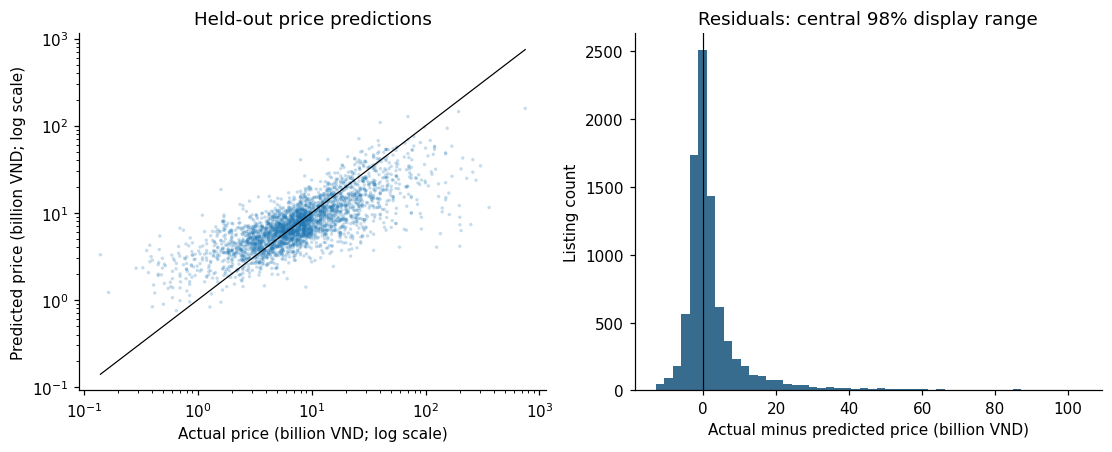

In [6]:
validation_prediction = predict_frame(model, validation)
test_prediction = predict_frame(model, test)
extra = {}
extra["vocabulary_size"] = len(model.named_steps["tfidf"].vocabulary_)
display(pd.Series({"Training empty text fraction": text_inputs(train).eq("").mean(),
                   "Test empty text fraction": text_inputs(test).eq("").mean(),
                   "Fitted vocabulary size": extra["vocabulary_size"]}).to_frame("Value"))
result, evaluation_table = record_result(
    "tfidf", manifest, parts, validation_prediction, test_prediction,
    selected_parameters, tuning_results, extra=extra)
display(evaluation_table.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}",
                                      "R2": "{:.4f}", "MAPE": "{:,.2f}"}))
diagnostics("tfidf", test.price, test_prediction)

In [7]:
comparison = comparison_table(manifest)
display(comparison.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}",
                                 "R2": "{:.4f}", "MAPE": "{:,.2f}"}))

,Model,MAE,RMSE,R2,MAPE
0,Dummy Regressor,"45,548,775,416","2,966,493,482,061",-0.0001,259.20
1,Median Price per sqm,"39,768,818,191","2,968,655,086,029",-0.0016,44.85
2,Ridge Regression,"42,681,233,989","2,971,055,734,676",-0.0032,74.73
3,Random Forest,"37,358,517,200","2,965,843,657,508",0.0003,36.77
4,LightGBM,"36,477,344,778","2,964,995,648,314",0.0009,28.59
5,CatBoost,"37,207,498,640","2,964,647,677,804",0.0011,35.56
6,TF-IDF + Ridge,"39,616,175,623","2,966,358,669,831",-0.0000,54.23
